# Lab 2 – Deep Learning avec PyTorch (MNIST)
CNN, Faster R-CNN, Transfer Learning (VGG16 / AlexNet) et Vision Transformer.
**Exécution : Colab → Exécution → Modifier le type d'exécution → GPU (T4).**

In [13]:
import time, math, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
torch.manual_seed(42); np.random.seed(42)
RESULTS = {}   # on stocke ici les métriques de chaque modèle

Device : cpu 


## Données MNIST
Le notebook cherche d'abord le dataset Kaggle (`hojjatk/mnist-dataset`), puis les CSV de `sample_data`, puis `torchvision`.
**Dans l'exécution présentée ici : CSV `sample_data` → 20 000 images d'entraînement / 10 000 de test** (et non 60 000).

In [17]:
# Fonctions génériques d'entraînement / évaluation pour les classifieurs
def evaluate(model, loader, prep=None):
    model.eval(); preds, trues, tot_loss = [], [], 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if prep: x = prep(x)
            out = model(x)
            tot_loss += F.cross_entropy(out, y, reduction="sum").item()
            preds += out.argmax(1).cpu().tolist(); trues += y.cpu().tolist()
    return tot_loss/len(trues), accuracy_score(trues, preds), f1_score(trues, preds, average="macro")

def fit(name, model, train_loader, test_loader, epochs=5, lr=1e-3, prep=None, weight_decay=0.0, params=None):
    model.to(device)
    opt = torch.optim.Adam(params or model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(epochs):
        model.train(); run, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if prep: x = prep(x)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
            run += loss.item()*len(y); n += len(y)
        tl, ta, tf1 = evaluate(model, test_loader, prep)
        hist["train_loss"].append(run/n); hist["test_loss"].append(tl); hist["test_acc"].append(ta)
        print(f"[{name}] epoch {ep+1}/{epochs}  train_loss={run/n:.4f}  test_loss={tl:.4f}  acc={ta:.4f}  f1={tf1:.4f}")
    if device.type == "cuda": torch.cuda.synchronize()
    elapsed = time.time() - t0
    tl, ta, tf1 = evaluate(model, test_loader, prep)
    RESULTS[name] = dict(Accuracy=ta, F1=tf1, Loss=tl, Temps_s=elapsed)
    return hist

## Partie 1 – Q1 : CNN from scratch
Hyper-paramètres : kernel 3×3, padding 1, stride 1, MaxPool 2×2, ReLU + BatchNorm,
Dropout 0.5 et weight decay (régularisation), optimiseur Adam (lr=1e-3).

In [19]:
import os, struct

def find_file(*keywords, root="/kaggle/input"):
    for d, _, files in os.walk(root):
        for f in files:
            name = f.lower().replace("_", "-").replace(".", "-")
            if all(k in name for k in keywords):
                return os.path.join(d, f)
    return None

def read_idx(path):
    with open(path, "rb") as f:
        data = f.read()
    ndim = struct.unpack(">I", data[:4])[0] & 0xFF
    dims = struct.unpack(">" + "I"*ndim, data[4:4+4*ndim])
    return np.frombuffer(data, dtype=np.uint8, offset=4+4*ndim).reshape(dims)

class ArrayDataset(torch.utils.data.Dataset):
    def __init__(self, x, y):   # x : (N,28,28) uint8 ou (N,1,28,28) float [0,1]
        x = torch.as_tensor(x).float()
        if x.max() > 1.5: x = x / 255
        self.x = x.view(-1, 1, 28, 28); self.y = torch.as_tensor(y).long()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], int(self.y[i])

tr_i, tr_l = find_file("train", "images"), find_file("train", "labels")
te_i, te_l = find_file("t10k", "images"),  find_file("t10k", "labels")

if all([tr_i, tr_l, te_i, te_l]):
    print("Source : dataset Kaggle (60000 images)")
    train_set = ArrayDataset(read_idx(tr_i), read_idx(tr_l))
    test_set  = ArrayDataset(read_idx(te_i), read_idx(te_l))
elif os.path.exists("/content/sample_data/mnist_test.csv"):
    print("Source : CSV sample_data (20000 images)")
    a = pd.read_csv("/content/sample_data/mnist_train_small.csv", header=None).values
    b = pd.read_csv("/content/sample_data/mnist_test.csv", header=None).values
    train_set = ArrayDataset(a[:, 1:], a[:, 0]); test_set = ArrayDataset(b[:, 1:], b[:, 0])
else:
    print("Source : téléchargement torchvision")
    t = transforms.ToTensor()
    train_set = datasets.MNIST("./data", train=True, download=True, transform=t)
    test_set  = datasets.MNIST("./data", train=False, download=True, transform=t)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=256, num_workers=2)
print(len(train_set), len(test_set))

Source : CSV sample_data (20000 images)
20000 10000


In [20]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 28 -> 14
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 14 -> 7
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 7 -> 3
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128*3*3, 128), nn.ReLU(), nn.Dropout(0.5), nn.Linear(128, 10))
    def forward(self, x): return self.classifier(self.features(x))

cnn = CNN()
h_cnn = fit("CNN", cnn, train_loader, test_loader, epochs=5, lr=1e-3, weight_decay=1e-4)

[CNN] epoch 1/5  train_loss=0.3726  test_loss=0.0633  acc=0.9795  f1=0.9794
[CNN] epoch 2/5  train_loss=0.0951  test_loss=0.0603  acc=0.9814  f1=0.9813
[CNN] epoch 3/5  train_loss=0.0740  test_loss=0.0522  acc=0.9820  f1=0.9820
[CNN] epoch 4/5  train_loss=0.0514  test_loss=0.0449  acc=0.9840  f1=0.9838
[CNN] epoch 5/5  train_loss=0.0497  test_loss=0.0357  acc=0.9883  f1=0.9882


## Q2 : Faster R-CNN
Faster R-CNN est un modèle de **détection** : il faut donc transformer MNIST en problème de détection.
Pour chaque image, la boîte englobante = zone des pixels non nuls, et la classe = chiffre + 1
(0 est réservé au fond). À l'inférence, la classe prédite = label de la détection au score le plus élevé.
Pour limiter le temps de calcul : sous-ensemble (6000 train / 1000 test) et backbone MobileNetV3-FPN.

In [22]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn

class MNISTDet(torch.utils.data.Dataset):
    def __init__(self, base): self.base = base
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        img, lab = self.base[i]
        ys, xs = torch.where(img[0] > 0.1)
        box = torch.tensor([[xs.min(), ys.min(), xs.max()+1, ys.max()+1]], dtype=torch.float32)
        return img.repeat(3, 1, 1), {"boxes": box, "labels": torch.tensor([lab+1])}

collate = lambda b: tuple(zip(*b))
rng = np.random.RandomState(0)
tr_idx = rng.choice(len(train_set), 6000, replace=False); te_idx = rng.choice(len(test_set), 1000, replace=False)
det_train = DataLoader(MNISTDet(Subset(train_set, tr_idx)), batch_size=32, shuffle=True, collate_fn=collate)
det_test  = DataLoader(MNISTDet(Subset(test_set, te_idx)), batch_size=64, collate_fn=collate)

frcnn = fasterrcnn_mobilenet_v3_large_fpn(weights=None, weights_backbone=None, num_classes=11,
                                          min_size=128, max_size=128).to(device)
params = [p for p in frcnn.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=0.01, momentum=0.9, weight_decay=5e-4)

def eval_det(model, loader):
    model.eval(); preds, trues = [], []
    with torch.no_grad():
        for imgs, tg in loader:
            outs = model([i.to(device) for i in imgs])
            for o, t in zip(outs, tg):
                preds.append(int(o["labels"][o["scores"].argmax()]) - 1 if len(o["scores"]) else -1)
                trues.append(int(t["labels"][0]) - 1)
    return accuracy_score(trues, preds), f1_score(trues, preds, average="macro")

EPOCHS_DET = 4
if device.type == "cuda": torch.cuda.synchronize()
t0 = time.time()
for ep in range(EPOCHS_DET):
    frcnn.train(); run, n = 0.0, 0
    for imgs, tg in det_train:
        imgs = [i.to(device) for i in imgs]; tg = [{k: v.to(device) for k, v in t.items()} for t in tg]
        loss = sum(frcnn(imgs, tg).values())
        opt.zero_grad(); loss.backward(); opt.step()
        run += loss.item(); n += 1
    acc, f1 = eval_det(frcnn, det_test)
    print(f"[Faster R-CNN] epoch {ep+1}/{EPOCHS_DET}  train_loss={run/n:.4f}  acc={acc:.4f}  f1={f1:.4f}")
if device.type == "cuda": torch.cuda.synchronize()
RESULTS["Faster R-CNN"] = dict(Accuracy=acc, F1=f1, Loss=run/n, Temps_s=time.time()-t0)
# NB : la "Loss" de Faster R-CNN est la somme des pertes (RPN + classification + régression de boîtes),
# elle n'est donc pas directement comparable à la cross-entropy des classifieurs.

[Faster R-CNN] epoch 1/4  train_loss=1.2243  acc=0.7840  f1=0.7836
[Faster R-CNN] epoch 2/4  train_loss=0.9785  acc=0.9090  f1=0.9031
[Faster R-CNN] epoch 3/4  train_loss=0.7297  acc=0.9410  f1=0.9398
[Faster R-CNN] epoch 4/4  train_loss=0.6265  acc=0.9810  f1=0.9806


## Q4 : VGG16 et AlexNet
MNIST est converti en 3 canaux, redimensionné en 64×64 et normalisé avec les statistiques ImageNet. Sous-ensemble de 10 000 images, 3 époques.
Le code tente de charger les poids ImageNet pour faire du fine-tuning (couches convolutives gelées, dernière couche 1000 → 10).
**Dans cette exécution, Internet était désactivé : les poids n'ont pas pu être téléchargés, les deux modèles ont donc été entraînés *from scratch*** (même architecture, sans transfer learning).

In [24]:
import os

mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1,3,1,1)
std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1,3,1,1)
def prep_imagenet(x):
    x = x.repeat(1, 3, 1, 1)
    x = F.interpolate(x, size=64, mode="bilinear", align_corners=False)
    return (x - mean) / std

sub_train = DataLoader(
    Subset(train_set, np.random.RandomState(1).choice(len(train_set), 10000, replace=False)),
    batch_size=64, shuffle=True, num_workers=2)

def build_model(arch):
    ctor, W = (models.vgg16, models.VGG16_Weights) if arch == "VGG16" else (models.alexnet, models.AlexNet_Weights)
    try:
        m = ctor(weights=W.IMAGENET1K_V1); pretrained = True
        for p in m.features.parameters(): p.requires_grad = False   # fine-tuning
    except Exception:
        m = ctor(weights=None); pretrained = False                   # pas d'Internet
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 10)
    return m, pretrained

hists = {}
for arch in ["AlexNet", "VGG16"]:
    m, pre = build_model(arch)
    name = f"{arch} (fine-tuned)" if pre else f"{arch} (from scratch)"
    lr = 1e-4 if (pre or arch == "VGG16") else 1e-3
    print(">>", name)
    hists[arch] = fit(name, m, sub_train, test_loader, epochs=3, lr=lr, prep=prep_imagenet,
                      params=[p for p in m.parameters() if p.requires_grad])

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
>> AlexNet (from scratch)
[AlexNet (from scratch)] epoch 1/3  train_loss=1.8490  test_loss=1.2662  acc=0.4994  f1=0.4233
[AlexNet (from scratch)] epoch 2/3  train_loss=0.5126  test_loss=0.2481  acc=0.9302  f1=0.9295
[AlexNet (from scratch)] epoch 3/3  train_loss=0.2247  test_loss=0.2431  acc=0.9444  f1=0.9440
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
>> VGG16 (from scratch)
[VGG16 (from scratch)] epoch 1/3  train_loss=0.9611  test_loss=0.2036  acc=0.9399  f1=0.9376
[VGG16 (from scratch)] epoch 2/3  train_loss=0.1270  test_loss=0.0948  acc=0.9730  f1=0.9728
[VGG16 (from scratch)] epoch 3/3  train_loss=0.0851  test_loss=0.0680  acc=0.9792  f1=0.9793


## Q3 + Q4 : comparaison (on ajoutera le ViT plus bas)

,Accuracy,F1,Loss,Temps_s
CNN,0.9883,0.9882,0.0357,119.8794
Faster R-CNN,0.9810,0.9806,0.6265,2904.6847
AlexNet (from scratch),0.9444,0.9440,0.2431,455.6579
VGG16 (from scratch),0.9792,0.9793,0.0680,3760.4762


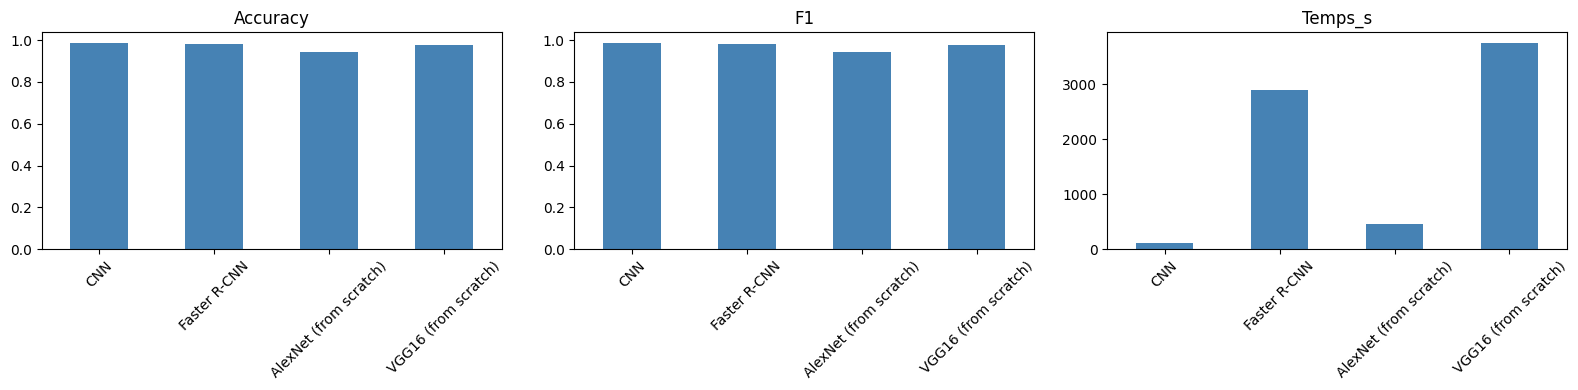

In [25]:
def show_results():
    df = pd.DataFrame(RESULTS).T.round(4)
    display(df)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for a, col in zip(ax, ["Accuracy", "F1", "Temps_s"]):
        df[col].plot.bar(ax=a, title=col, color="steelblue"); a.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()
show_results()

## Partie 2 – Vision Transformer (ViT) from scratch
Étapes du tutoriel : découpage en patches → projection linéaire → token [CLS] → encodage positionnel
→ blocs Transformer (LayerNorm, Multi-Head Self-Attention, MLP, connexions résiduelles) → tête de classification.
MNIST 28×28, patches 7×7 → 16 patches + 1 token CLS.

In [26]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=28, patch=7, in_ch=1, dim=64):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, dim, kernel_size=patch, stride=patch)  # équivalent patchify + Linear
        self.n_patches = (img_size // patch) ** 2
    def forward(self, x): return self.proj(x).flatten(2).transpose(1, 2)    # (B, N, dim)

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.h, self.d = heads, dim // heads
        self.qkv = nn.Linear(dim, dim*3); self.out = nn.Linear(dim, dim)
    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, self.d).permute(2, 0, 3, 1, 4)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.d)
        att = att.softmax(-1)
        return self.out((att @ v).transpose(1, 2).reshape(B, N, D))

class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4, drop=0.1):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = MultiHeadSelfAttention(dim, heads)
        self.mlp = nn.Sequential(nn.Linear(dim, dim*mlp_ratio), nn.GELU(), nn.Dropout(drop),
                                 nn.Linear(dim*mlp_ratio, dim), nn.Dropout(drop))
    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

class ViT(nn.Module):
    def __init__(self, img_size=28, patch=7, in_ch=1, dim=64, depth=4, heads=4, n_classes=10):
        super().__init__()
        self.patch = PatchEmbedding(img_size, patch, in_ch, dim)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.randn(1, self.patch.n_patches + 1, dim) * 0.02)
        self.blocks = nn.Sequential(*[TransformerBlock(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim); self.head = nn.Linear(dim, n_classes)
    def forward(self, x):
        x = self.patch(x)
        x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], 1) + self.pos
        x = self.norm(self.blocks(x))
        return self.head(x[:, 0])

vit = ViT()
print("Paramètres ViT :", sum(p.numel() for p in vit.parameters()))
h_vit = fit("ViT (from scratch)", vit, train_loader, test_loader, epochs=10, lr=1e-3, weight_decay=1e-4)

Paramètres ViT : 205066
[ViT (from scratch)] epoch 1/10  train_loss=1.3144  test_loss=0.6455  acc=0.7969  f1=0.7912
[ViT (from scratch)] epoch 2/10  train_loss=0.4523  test_loss=0.3005  acc=0.9074  f1=0.9063
[ViT (from scratch)] epoch 3/10  train_loss=0.2667  test_loss=0.2422  acc=0.9252  f1=0.9248
[ViT (from scratch)] epoch 4/10  train_loss=0.2004  test_loss=0.1809  acc=0.9459  f1=0.9453
[ViT (from scratch)] epoch 5/10  train_loss=0.1486  test_loss=0.1879  acc=0.9458  f1=0.9454
[ViT (from scratch)] epoch 6/10  train_loss=0.1277  test_loss=0.1622  acc=0.9497  f1=0.9495
[ViT (from scratch)] epoch 7/10  train_loss=0.1101  test_loss=0.1455  acc=0.9582  f1=0.9578
[ViT (from scratch)] epoch 8/10  train_loss=0.1038  test_loss=0.1507  acc=0.9555  f1=0.9552
[ViT (from scratch)] epoch 9/10  train_loss=0.0865  test_loss=0.1313  acc=0.9613  f1=0.9612
[ViT (from scratch)] epoch 10/10  train_loss=0.0834  test_loss=0.1330  acc=0.9612  f1=0.9609


## Résultats finaux et courbes

,Accuracy,F1,Loss,Temps_s
CNN,0.9883,0.9882,0.0357,119.8794
Faster R-CNN,0.9810,0.9806,0.6265,2904.6847
AlexNet (from scratch),0.9444,0.9440,0.2431,455.6579
VGG16 (from scratch),0.9792,0.9793,0.0680,3760.4762
ViT (from scratch),0.9612,0.9609,0.1330,177.6944


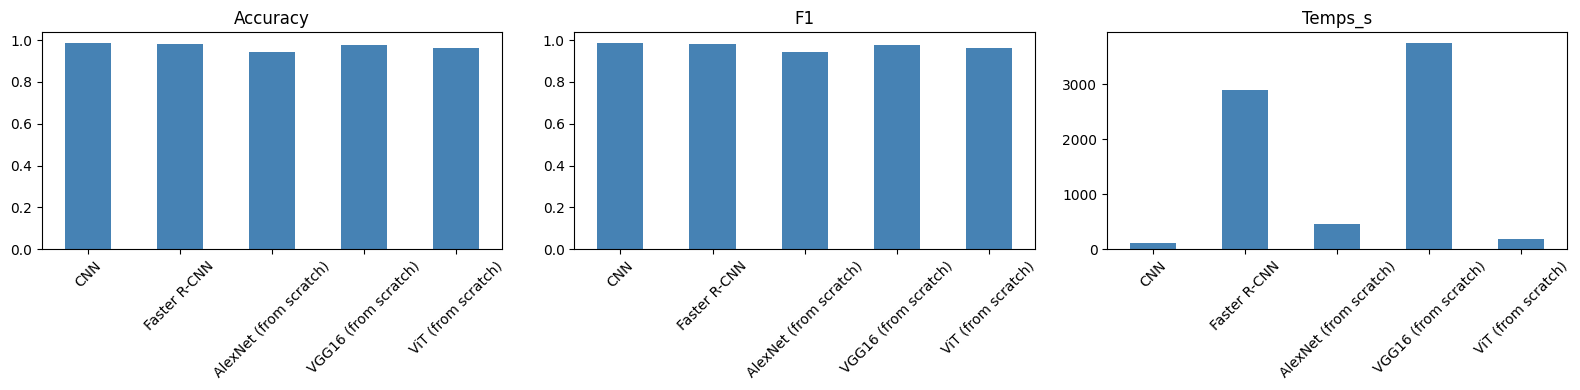

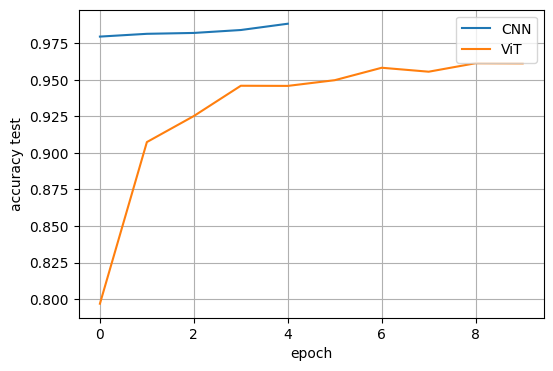

In [27]:
show_results()
plt.figure(figsize=(6,4))
plt.plot(h_cnn["test_acc"], label="CNN"); plt.plot(h_vit["test_acc"], label="ViT")
plt.xlabel("epoch"); plt.ylabel("accuracy test"); plt.legend(); plt.grid(); plt.show()

## Interprétation des résultats obtenus

| Modèle | Accuracy | F1 | Loss | Temps (s) |
|---|---|---|---|---|
| CNN | 0.9883 | 0.9882 | 0.0357 | 120 |
| Faster R-CNN | 0.9810 | 0.9806 | 0.6265* | 2905 |
| AlexNet (from scratch) | 0.9444 | 0.9440 | 0.2431 | 456 |
| VGG16 (from scratch) | 0.9792 | 0.9793 | 0.0680 | 3760 |
| ViT (from scratch) | 0.9612 | 0.9609 | 0.1330 | 178 |

\* somme des pertes de détection (RPN + classification + boîtes), non comparable à la cross-entropy.

- **CNN** : meilleur résultat (98,8 %) et le plus rapide (120 s) grâce à ses biais inductifs (localité, partage de poids).
- **Faster R-CNN** : 98,1 %, mais ~24× plus lent : architecture de détection surdimensionnée pour de la classification.
- **AlexNet / VGG16 (from scratch)** : VGG16 atteint 97,9 % mais coûte ~31× le temps du CNN ; AlexNet reste à 94,4 % après 3 époques.
- **ViT** : 96,1 % en 10 époques, encore en progression ; sans biais inductif, il apprend moins vite que le CNN sur un petit dataset (20 000 images).
- **Conclusion** : sur MNIST, le CNN offre le meilleur compromis précision / coût. Le transfer learning n'a pas pu être évalué (poids ImageNet indisponibles).

## Synthèse personnelle
J'ai appris à construire et entraîner un CNN avec PyTorch, à adapter un modèle de détection (Faster R-CNN) à une tâche de classification, à comparer des modèles avec plusieurs métriques (accuracy, F1, loss, temps), à implémenter un Vision Transformer from scratch (patch embedding, self-attention, token CLS), et à gérer les contraintes pratiques (absence d'Internet, GPU, temps de calcul).